In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
import shap
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("/content/dataset-uci.csv")
df

,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
314,1,49,0,0,0,0,0,0,178,88.8,...,55.0,81.0,28.0,50.0,90.0,0.98,94.50,6.2,16.5,8.3
315,1,31,1,0,0,0,0,0,157,53.4,...,58.0,64.0,24.0,16.0,38.0,0.50,128.50,0.0,12.5,24.0
316,1,58,0,0,0,0,0,0,172,96.6,...,45.0,168.0,21.0,27.0,94.0,1.04,83.23,0.0,15.4,15.7
317,1,37,1,0,0,0,0,0,177,88.4,...,33.0,253.0,40.0,22.0,115.0,1.01,98.23,0.4,16.0,33.3


In [ ]:
duplicatecount = df.duplicated().sum()
print("Num of duplicate rows:", duplicatecount)


Num of duplicate rows: 0


In [ ]:
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
Gallstone Status                                  0
Age                                               0
Gender                                            0
Comorbidity                                       0
Coronary Artery Disease (CAD)                     0
Hypothyroidism                                    0
Hyperlipidemia                                    0
Diabetes Mellitus (DM)                            0
Height                                            0
Weight                                            0
Body Mass Index (BMI)                             0
Total Body Water (TBW)                            0
Extracellular Water (ECW)                         0
Intracellular Water (ICW)                         0
Extracellular Fluid/Total Body Water (ECF/TBW)    0
Total Body Fat Ratio (TBFR) (%)                   0
Lean Mass (LM) (%)                                0
Body Protein Content (Protein) (%)                0
Visceral Fat Rating (VFR)            

In [ ]:
from scipy.stats import zscore
import numpy as np

X_no_target = df.drop("Gallstone Status", axis=1)

z_scores = np.abs(zscore(X_no_target))
outliers = (z_scores > 3).any(axis=1)

print("Number of outlier rows:", outliers.sum())

Number of outlier rows: 74


In [ ]:
featurestodrop = ["Height","Weight","Extracellular Water (ECW)","Intracellular Water (ICW)"]

df = df.drop(columns=featurestodrop)

In [ ]:
df

,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Body Mass Index (BMI),Total Body Water (TBW),...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,27.1,52.9,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,30.5,43.1,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,31.2,47.2,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,24.0,41.4,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,28.3,51.4,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
314,1,49,0,0,0,0,0,0,28.0,47.6,...,55.0,81.0,28.0,50.0,90.0,0.98,94.50,6.2,16.5,8.3
315,1,31,1,0,0,0,0,0,21.7,29.3,...,58.0,64.0,24.0,16.0,38.0,0.50,128.50,0.0,12.5,24.0
316,1,58,0,0,0,0,0,0,32.7,49.2,...,45.0,168.0,21.0,27.0,94.0,1.04,83.23,0.0,15.4,15.7
317,1,37,1,0,0,0,0,0,28.2,50.2,...,33.0,253.0,40.0,22.0,115.0,1.01,98.23,0.4,16.0,33.3


In [ ]:
X = df.drop("Gallstone Status", axis=1)
y = df["Gallstone Status"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

num_features = X_train.columns

preprocessor = ColumnTransformer([("num", StandardScaler(), num_features)])


In [ ]:
pipelines = {
    "Logistic": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    "SVM": Pipeline([
        ("preprocessor", preprocessor),
        ("model", SVC(probability=True))
    ]),
    "RandomForest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(random_state=42))
    ]),
    "KNN": Pipeline([
        ("preprocessor", preprocessor),
        ("model", KNeighborsClassifier())
    ])
}

In [ ]:
param_grids = {
    "Logistic": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__penalty": ["l2"]
    },
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"]
    },
    "RandomForest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20]
    },
    "KNN": {
        "model__n_neighbors": [3,5,7,9],
        "model__weights": ["uniform","distance"]
    }
}

In [ ]:
best_models = {}
cv_results = []

for name in pipelines:
    print(f"\n Tuning {name}...")
    grid = GridSearchCV(
        pipelines[name],
        param_grids[name],
        cv=5,
        scoring="accuracy",
        n_jobs=-1,
        return_train_score=True
    )
    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    for i in range(len(grid.cv_results_["params"])):
        cv_results.append([
            name,
            grid.cv_results_["params"][i],
            grid.cv_results_["mean_train_score"][i],
            grid.cv_results_["mean_test_score"][i]
        ])

    print("Best Params:", grid.best_params_)
    print("Best CV Accuracy:", grid.best_score_)


 Tuning Logistic...
Best Params: {'model__C': 10, 'model__penalty': 'l2'}
Best CV Accuracy: 0.7725490196078431

 Tuning SVM...
Best Params: {'model__C': 10, 'model__kernel': 'linear'}
Best CV Accuracy: 0.8

 Tuning RandomForest...
Best Params: {'model__max_depth': None, 'model__n_estimators': 100}
Best CV Accuracy: 0.7529411764705882

 Tuning KNN...
Best Params: {'model__n_neighbors': 9, 'model__weights': 'distance'}
Best CV Accuracy: 0.6588235294117647


In [ ]:
cv_results_df = pd.DataFrame(cv_results, columns=[
    "Algorithm", "Hyperparameters", "Train Accuracy", "Validation Accuracy"
])


cv_results_df["Train Accuracy"] = cv_results_df["Train Accuracy"].round(3)
cv_results_df["Validation Accuracy"] = cv_results_df["Validation Accuracy"].round(3)

cv_results_df = cv_results_df.sort_values(by="Algorithm").reset_index(drop=True)

def format_hyperparams(d):
    return ', '.join([f"{k.split('__')[1]}={v}" for k, v in d.items()])

cv_results_df["Hyperparameters"] = cv_results_df["Hyperparameters"].apply(format_hyperparams)

print(cv_results_df.head(22).to_markdown(index=False))

| Algorithm    | Hyperparameters                  |   Train Accuracy |   Validation Accuracy |
|:-------------|:---------------------------------|-----------------:|----------------------:|
| KNN          | n_neighbors=9, weights=distance  |            1     |                 0.659 |
| KNN          | n_neighbors=7, weights=distance  |            1     |                 0.631 |
| KNN          | n_neighbors=7, weights=uniform   |            0.743 |                 0.624 |
| KNN          | n_neighbors=5, weights=distance  |            1     |                 0.608 |
| KNN          | n_neighbors=5, weights=uniform   |            0.772 |                 0.604 |
| KNN          | n_neighbors=3, weights=distance  |            1     |                 0.612 |
| KNN          | n_neighbors=3, weights=uniform   |            0.814 |                 0.608 |
| KNN          | n_neighbors=9, weights=uniform   |            0.747 |                 0.655 |
| Logistic     | C=0.01, penalty=l2               

In [ ]:
print("\nfinal results")
test_summary = []

for name, model in best_models.items():
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    test_summary.append([name, acc, prec, rec, f1])

    print(f"\n{name}")
    print("Accuracy:", acc)
    print("Precision:", prec)
    print("Recall:", rec)
    print("F1:", f1)
    print(classification_report(y_test, y_pred))


final results

Logistic
Accuracy: 0.8125
Precision: 0.7941176470588235
Recall: 0.84375
F1: 0.8181818181818182
              precision    recall  f1-score   support

           0       0.83      0.78      0.81        32
           1       0.79      0.84      0.82        32

    accuracy                           0.81        64
   macro avg       0.81      0.81      0.81        64
weighted avg       0.81      0.81      0.81        64


SVM
Accuracy: 0.796875
Precision: 0.7878787878787878
Recall: 0.8125
F1: 0.8
              precision    recall  f1-score   support

           0       0.81      0.78      0.79        32
           1       0.79      0.81      0.80        32

    accuracy                           0.80        64
   macro avg       0.80      0.80      0.80        64
weighted avg       0.80      0.80      0.80        64


RandomForest
Accuracy: 0.8125
Precision: 0.7941176470588235
Recall: 0.84375
F1: 0.8181818181818182
              precision    recall  f1-score   support

   

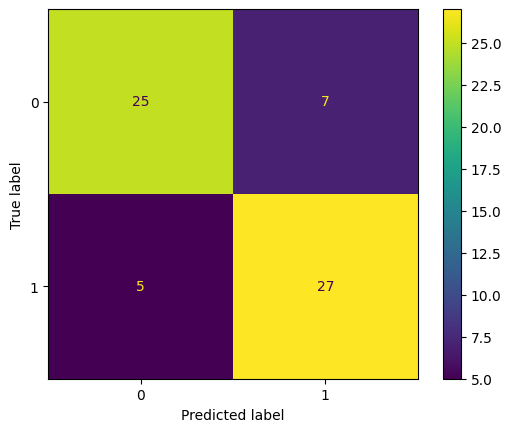

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
best_model = best_models["RandomForest"]
y_pred = best_model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

In [ ]:
rf_model = best_models["RandomForest"].named_steps["model"]
feature_names = X_train.columns
importances = rf_model.feature_importances_

fi_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

print("Top 10 Important Features")
print(fi_df.head(10))

Top 10 Important Features
                                           Feature  Importance
31                        C-Reactive Protein (CRP)    0.152304
33                                       Vitamin D    0.101984
9   Extracellular Fluid/Total Body Water (ECF/TBW)    0.052870
26                  Aspartat Aminotransferaz (AST)    0.043898
19                 Visceral Muscle Area (VMA) (Kg)    0.038589
17                         Total Fat Content (TFC)    0.032031
29                                      Creatinine    0.031302
32                                Hemoglobin (HGB)    0.030888
24                  High Density Lipoprotein (HDL)    0.030565
28                      Alkaline Phosphatase (ALP)    0.030438


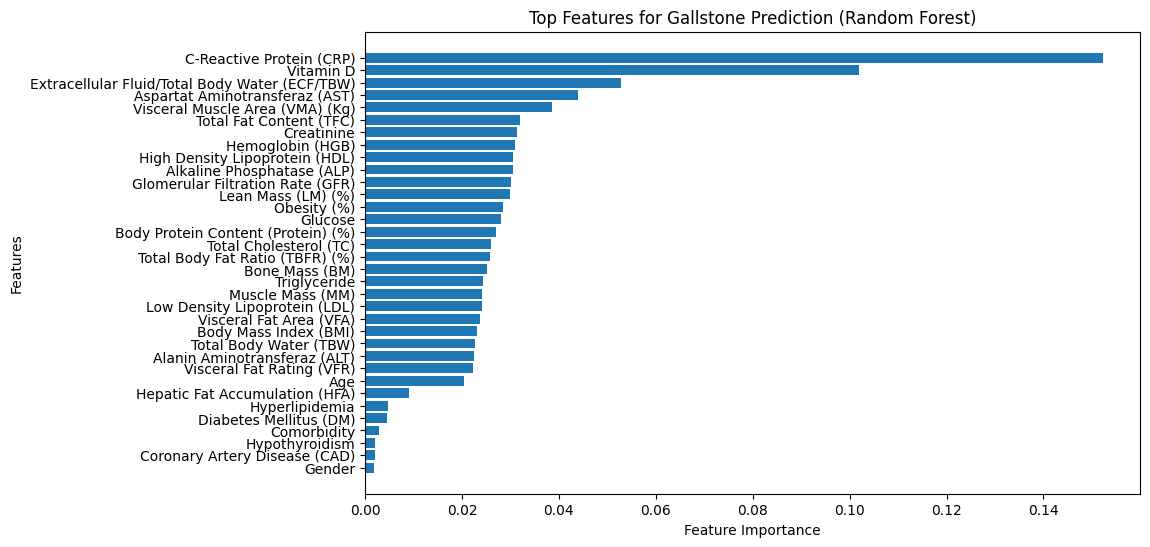

In [ ]:
plt.figure(figsize=(10,6))
plt.barh(fi_df['Feature'], fi_df['Importance'])
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top Features for Gallstone Prediction (Random Forest)")
plt.gca().invert_yaxis()
plt.show()

In [ ]:
from lime.lime_tabular import LimeTabularExplainer

X_train_df = X_train.copy()
X_test_df = X_test.copy()

explainer = LimeTabularExplainer(
    training_data=X_train_df.values,
    feature_names=X_train_df.columns.tolist(),
    class_names=['No Gallstone', 'Gallstone'],
    mode='classification')

def predict_fn(data):

    return best_models["RandomForest"].predict_proba(pd.DataFrame(data, columns=X_train_df.columns))

i = 2
exp = explainer.explain_instance(
    data_row=X_test_df.iloc[i].values,
    predict_fn=predict_fn,
    num_features=10)

exp.show_in_notebook(show_table=True)
